# **Performance analysis and comparison of Classification Algorithms(Logistic Regression, KNeighborsClassifier,SVM,DecisionTreeClassifier,SVC,RandomForestClassification) on Crop Recommendation data**

Guide: Dr. Rambabu Pemula

Authors:

*   Chanchal Sharma 24911A6677
*   Sonu Seervi 24911A66C0
*   Mahween fatima 25915A6611






# PROBLEM STATEMENT
Agriculture plays an important role in economic development, and selecting the right crop is essential for improving agricultural productivity. Crop selection depends on various factors such as soil nutrients (Nitrogen, Phosphorus, Potassium), temperature, humidity, pH, and rainfall. Traditional crop selection methods may not always provide accurate results due to changing environmental and soil conditions.

This project aims to develop a machine learning-based crop recommendation system using the Crop Recommendation dataset. Six classification algorithms—Logistic Regression, K-Nearest Neighbors (KNN), SVM, Decision Tree, SVC, and Random Forest—will be implemented and evaluated.


# STEPS:
1.Importing the libraries
2.Reading the Penguins Classification dataset.
3.Preprocessing.
4.Split the dataset into training and testing.
5.Build the model. (Logistic Regression,KNN,SVM,DecisionTree)
6.Evaluate the performance

In [ ]:
# Importing required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Importing machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Importing evaluation metrics
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2.READ CROP-RECOMMENDATION DATASET
Reading a dataset involves loading data from a le(like CSV,Excel, or JSON) into a program, allowing yo


In [ ]:
df=pd.read_csv('/content/drive/MyDrive/Crop_recommendation.csv')

In [ ]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [ ]:
print("Shape of dataset:", df.shape)

Shape of dataset: (2200, 8)


In [ ]:
df

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice
...,...,...,...,...,...,...,...,...
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,coffee
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,coffee
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,coffee
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,coffee


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [ ]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


DATA PREPROCESSING

In [ ]:
df.isnull().sum()

,0
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
from sklearn import preprocessing

le = preprocessing.LabelEncoder()
le.fit(df['label'])
df['label'] = le.fit_transform(df['label'])

print(df['label'])

0       20
1       20
2       20
3       20
4       20
        ..
2195     5
2196     5
2197     5
2198     5
2199     5
Name: label, Length: 2200, dtype: int64


SEPARATE FEATURES AND TARGET VARIABLES

In [ ]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

Features (X):
    N   P   K  temperature   humidity        ph    rainfall
0  90  42  43    20.879744  82.002744  6.502985  202.935536
1  85  58  41    21.770462  80.319644  7.038096  226.655537
2  60  55  44    23.004459  82.320763  7.840207  263.964248
3  74  35  40    26.491096  80.158363  6.980401  242.864034
4  78  42  42    20.130175  81.604873  7.628473  262.717340

Target (y):
0    20
1    20
2    20
3    20
4    20
Name: label, dtype: int64


SPLITTING THE DATA INTO TRAINING AND TESTING

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1760, 7)
X_test shape: (440, 7)
y_train shape: (1760,)
y_test shape: (440,)


In [ ]:
X_train

,N,P,K,temperature,humidity,ph,rainfall
1656,17,16,14,16.396243,92.181519,6.625539,102.944161
752,37,79,19,27.543848,69.347863,7.143943,69.408782
892,7,73,25,27.521856,63.132153,7.288057,45.208411
1041,101,70,48,25.360592,75.031933,6.012697,116.553145
1179,0,17,30,35.474783,47.972305,6.279134,97.790725
...,...,...,...,...,...,...,...
1638,10,5,5,21.213070,91.353492,7.817846,112.983436
1095,108,94,47,27.359116,84.546250,6.387431,90.812505
1130,11,36,31,27.920633,51.779659,6.475449,100.258567
1294,11,124,204,13.429886,80.066340,6.361141,71.400430


In [ ]:
y_train

,label
1656,16
752,2
892,10
1041,1
1179,12
...,...
1638,16
1095,1
1130,12
1294,7


LOGISTIC REGRESSION

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_lr = lr_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 95.22727272727273 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      1.00      1.00        21
           2       0.85      0.85      0.85        20
           3       1.00      1.00      1.00        26
           4       1.00      1.00      1.00        27
           5       0.94      1.00      0.97        17
           6       0.80      0.94      0.86        17
           7       1.00      1.00      1.00        14
           8       0.87      0.87      0.87        23
           9       1.00      1.00      1.00        20
          10       0.77      0.91      0.83        11
          11       0.94      0.81      0.87        21
          12       1.00      1.00      1.00        19
          13       0.91      0.88      0.89        24
          14       1.00      1.00      1.00        19
          15       1.00      1.00      1.00        17
       

In [ ]:
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred_lr
})

print(comparison.head(10))

      Actual  Predicted
1451      15         15
1334      21         21
1761      17         17
1735      17         17
1576       0          0
1110      12         12
1594       0          0
530       13         13
651       14         14
819       10         10


In [ ]:
import pandas as pd

new_data = pd.DataFrame([{
    'N': 90,
    'P': 42,
    'K': 43,
    'temperature': 20.8,
    'humidity': 82,
    'ph': 6.5,
    'rainfall': 202
}])

prediction = lr_model.predict(new_data)

crop_name = le.inverse_transform(prediction)

print("Recommended Crop:", crop_name[0])

Recommended Crop: rice


In [ ]:
print("Model: Logistic Regression")
print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("Recommended Crop:", crop_name[0])

Model: Logistic Regression
Model Accuracy: 95.23 %
Recommended Crop: rice


SVM MODEL

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

svm_model = SVC(kernel='rbf')

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", svm_accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 96.13636363636363 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      1.00      1.00        21
           2       0.91      1.00      0.95        20
           3       1.00      1.00      1.00        26
           4       1.00      1.00      1.00        27
           5       1.00      0.94      0.97        17
           6       0.85      1.00      0.92        17
           7       1.00      1.00      1.00        14
           8       0.77      1.00      0.87        23
           9       0.95      1.00      0.98        20
          10       0.79      1.00      0.88        11
          11       1.00      0.86      0.92        21
          12       1.00      1.00      1.00        19
          13       1.00      0.88      0.93        24
          14       1.00      1.00      1.00        19
          15       1.00      1.00      1.00        17
          16       1.00

DECISION TREE CLASSIFIER

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", dt_accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 98.63636363636363 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      1.00      1.00        21
           2       0.95      1.00      0.98        20
           3       1.00      1.00      1.00        26
           4       0.96      1.00      0.98        27
           5       1.00      1.00      1.00        17
           6       1.00      1.00      1.00        17
           7       1.00      1.00      1.00        14
           8       0.92      0.96      0.94        23
           9       1.00      1.00      1.00        20
          10       0.92      1.00      0.96        11
          11       1.00      0.95      0.98        21
          12       1.00      1.00      1.00        19
          13       1.00      0.92      0.96        24
          14       1.00      1.00      1.00        19
          15       1.00      1.00      1.00        17
          16 

RANDOM FOREST CLASSIFIER

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 99.31818181818181 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      1.00      1.00        21
           2       1.00      1.00      1.00        20
           3       1.00      1.00      1.00        26
           4       1.00      1.00      1.00        27
           5       1.00      1.00      1.00        17
           6       1.00      1.00      1.00        17
           7       1.00      1.00      1.00        14
           8       0.92      1.00      0.96        23
           9       1.00      1.00      1.00        20
          10       0.92      1.00      0.96        11
          11       1.00      1.00      1.00        21
          12       1.00      1.00      1.00        19
          13       1.00      0.96      0.98        24
          14       1.00      1.00      1.00        19
          15       1.00      1.00      1.00        17
          16 

K-Nearest Neighbors(KNN)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", knn_accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

KNN Accuracy: 97.04545454545455 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      1.00      1.00        21
           2       0.95      1.00      0.98        20
           3       1.00      1.00      1.00        26
           4       1.00      1.00      1.00        27
           5       1.00      0.94      0.97        17
           6       0.94      1.00      0.97        17
           7       1.00      1.00      1.00        14
           8       0.76      0.96      0.85        23
           9       0.95      1.00      0.98        20
          10       0.85      1.00      0.92        11
          11       1.00      0.95      0.98        21
          12       1.00      1.00      1.00        19
          13       1.00      0.92      0.96        24
          14       1.00      1.00      1.00        19
          15       1.00      1.00      1.00        17
          16       1.00

K-Means

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Select the input features
X_kmeans = X.copy()

# Train the K-Means model
kmeans_model = KMeans(
    n_clusters=22,
    random_state=42,
    n_init=10
)

kmeans_model.fit(X_kmeans)

# Get cluster assignments
y_pred_kmeans = kmeans_model.labels_

print("K-Means Clustering Completed!")
print("Number of clusters:", kmeans_model.n_clusters)
print("Silhouette Score:", silhouette_score(X_kmeans, y_pred_kmeans))

K-Means Clustering Completed!
Number of clusters: 22
Silhouette Score: 0.4096904403579425


In [ ]:
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(y, y_pred_kmeans)

print("K-Means Adjusted Rand Index:", ari)

K-Means Adjusted Rand Index: 0.6625041011208219


PERFORMANCE METRICS COMPARISON

In [ ]:
import pandas as pd

model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'SVM',
        'Decision Tree',
        'Random Forest',
        'KNN'
    ],
    'Accuracy (%)': [
        accuracy * 100,
        svm_accuracy * 100,
        dt_accuracy * 100,
        rf_accuracy * 100,
        knn_accuracy * 100
    ]
})

model_comparison = model_comparison.sort_values(
    by='Accuracy (%)', ascending=False
).reset_index(drop=True)

print("Model Accuracy Comparison:")
print(model_comparison.to_string(index=False))

best_model = model_comparison.iloc[0]

print("\nBest Model:", best_model['Model'])
print("Best Accuracy:", round(best_model['Accuracy (%)'], 2), "%")

Model Accuracy Comparison:
              Model  Accuracy (%)
      Random Forest     99.318182
      Decision Tree     98.636364
                KNN     97.045455
                SVM     96.136364
Logistic Regression     95.227273

Best Model: Random Forest
Best Accuracy: 99.32 %


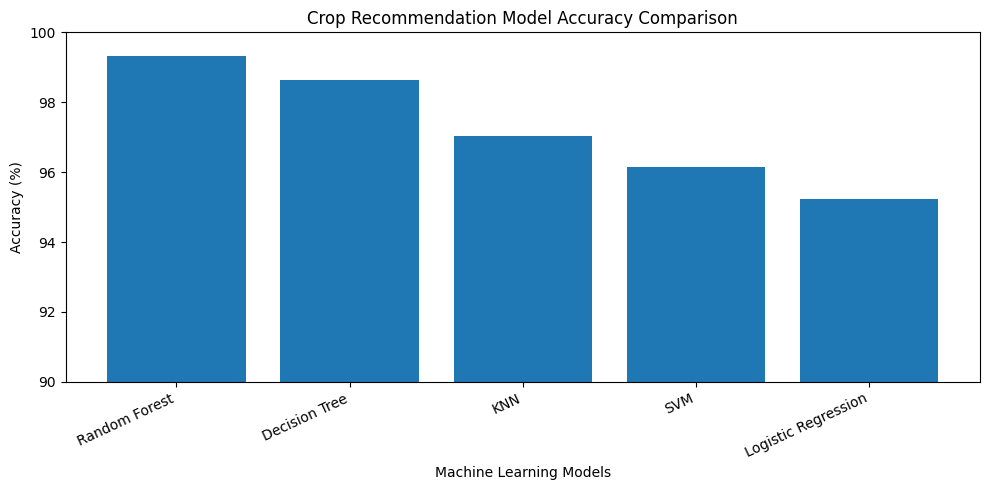

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    model_comparison['Model'],
    model_comparison['Accuracy (%)']
)

plt.title('Crop Recommendation Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy (%)')
plt.ylim(90, 100)
plt.xticks(rotation=25, ha='right')

plt.tight_layout()
plt.show()